# Fase 2 — Modelo Decision Tree
## Estimador de área cosechada (EVA Colombia)

**Inteligencia Artificial I — Grupo C2, periodo 2026-2** · Responsable de este modelo: **Juan David Barrera**

**Objetivo:** dado un municipio, un cultivo, un año y el área sembrada, estimar el **área cosechada**
(hectáreas). Es un problema de **regresión**. Este notebook entrena el modelo **Decision Tree**; los otros
integrantes entrenan Random Forest, Red neuronal (MLP) y SVR con la **misma limpieza, el mismo bloque común,
la misma división de años y el mismo formato de salida**, para poder unir los 4 resultados.

**Orden de ejecución (no cambiarlo):**
1. Librerías
2. Limpieza (igual en los 4 notebooks)
3. Bloque común (igual en los 4 notebooks)
4. Modelo Decision Tree: búsqueda de hiperparámetros con 2022 → modelo final → prueba 2023–2025
5. Análisis de resultados (gráficas para las diapositivas)

**Archivos necesarios en Drive (`MiUnidad/EVA/`):** `EVA_2007_2018.csv`, `EVA_2019_2025.csv`,
`PANEL_CARACTERISTICAS_GENERALES_2021.csv`.

| Bloque | Años | Uso |
|---|---|---|
| Entrenamiento | 2007–2021 (sin 2018) | Ajustar el modelo |
| Validación | 2022 | Elegir hiperparámetros |
| Prueba | 2023–2025 | Evaluar **una sola vez** al final |


# 1. Librerías

In [1]:
# =========================================================
# Librerias que vamos a usar
# =========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
print("Librerias cargadas")

Librerias cargadas


# 2. Limpieza de los datos (común a los 4 modelos)

**No modificar esta celda.** Es la limpieza acordada por el equipo (Anexo A del documento de contexto).
Produce la tabla `datos`: **238.350 filas × 16 columnas**, una fila por municipio + cultivo + estado
físico + año. Resumen de lo que hace:

1. Carga los dos CSV como texto (formato colombiano de números y códigos DANE con ceros a la izquierda).
2. Deja solo las 14 columnas que existen en los dos archivos.
3. Convierte números y normaliza códigos DANE.
4. Texto en mayúsculas y sin tildes.
5. Estandariza nombres de cultivo y de estado físico.
6. Deja solo los cultivos presentes en los dos archivos, con un solo grupo y un solo ciclo.
7. Une los archivos y elimina 2006 y 2018 (años incompletos).
8. Pasa de semestres a años.
9. Regla de arrastre: elimina cosechas mayores al área disponible.
10. Agrega la altura de cada municipio (panel CEDE).
11. Revisión final.


In [2]:
# =====================================================================
# LIMPIEZA DEFINITIVA DE LOS ARCHIVOS EVA (2007-2018 y 2019-2025)
# Resultado: la tabla "datos" con UNA fila por municipio + cultivo +
# estado fisico + anio, lista para entrenar los modelos.
# =====================================================================

import pandas as pd
import numpy as np

# =========================================================
# PASO 1: Cargar los dos archivos desde Google Drive
# =========================================================
print("PASO 1: Cargar los dos archivos desde Google Drive")
# Los archivos deben estar guardados en:  MiUnidad / EVA /
from google.colab import drive
drive.mount("/content/drive")

RUTA = "/content/drive/MyDrive/EVA/"

# Leemos todo como texto: los numeros vienen en formato colombiano
# ("1.247.206,27") y los codigos DANE tienen ceros a la izquierda ("05001").
eva_viejo = pd.read_csv(RUTA + "EVA_2007_2018.csv", dtype=str)
eva_nuevo = pd.read_csv(RUTA + "EVA_2019_2025.csv", dtype=str)

print("EVA 2007-2018:", eva_viejo.shape[0], "filas y", eva_viejo.shape[1], "columnas")
print("EVA 2019-2025:", eva_nuevo.shape[0], "filas y", eva_nuevo.shape[1], "columnas")
print("PASO 1: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 2: Dejar solo las columnas necesarias, con el mismo nombre
# =========================================================
print("PASO 2: Dejar solo las columnas necesarias, con el mismo nombre")

# El archivo viejo trae saltos de linea dentro de los nombres
# ("Área Sembrada\n(ha)"): los cambiamos por un espacio.
eva_viejo.columns = [" ".join(nombre.split()) for nombre in eva_viejo.columns]
eva_nuevo.columns = [" ".join(nombre.split()) for nombre in eva_nuevo.columns]

# Solo columnas que existen en LOS DOS archivos y que se usan despues.
# (El rendimiento no se carga: se recalcula al final con la formula.)
nombres_nuevo = {
    "Código Dane departamento":  "cod_dep",
    "Departamento":              "departamento",
    "Código Dane municipio":     "cod_mun",
    "Municipio":                 "municipio",
    "Grupo cultivo":             "grupo",
    "Cultivo":                   "cultivo",
    "Desagregación cultivo":     "desagregacion",
    "Año":                       "anio",
    "Periodo":                   "periodo",
    "Área sembrada":             "area_sembrada",
    "Área cosechada":            "area_cosechada",
    "Producción":                "produccion",
    "Ciclo del cultivo":         "ciclo",
    "Estado físico del cultivo": "estado_fisico",
}
nombres_viejo = {
    "CÓD. DEP.":                                     "cod_dep",
    "DEPARTAMENTO":                                  "departamento",
    "CÓD. MUN.":                                     "cod_mun",
    "MUNICIPIO":                                     "municipio",
    "GRUPO DE CULTIVO":                              "grupo",
    "CULTIVO":                                       "cultivo",
    "DESAGREGACIÓN REGIONAL Y/O SISTEMA PRODUCTIVO": "desagregacion",
    "AÑO":                                           "anio",
    "PERIODO":                                       "periodo",
    "Área Sembrada (ha)":                            "area_sembrada",
    "Área Cosechada (ha)":                           "area_cosechada",
    "Producción (t)":                                "produccion",
    "CICLO DE CULTIVO":                              "ciclo",
    "ESTADO FISICO PRODUCCION":                      "estado_fisico",
}
COLUMNAS = list(nombres_nuevo.values())
eva_nuevo = eva_nuevo.rename(columns=nombres_nuevo)[COLUMNAS].copy()
eva_viejo = eva_viejo.rename(columns=nombres_viejo)[COLUMNAS].copy()

print("Columnas que se conservan:", COLUMNAS)
print("PASO 2: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 3: Convertir los numeros y los codigos DANE
# =========================================================
print("PASO 3: Convertir los numeros y los codigos DANE")

def convertir_a_numero(columna):
    # "1.247.206,27" -> 1247206.27  (el punto separa miles, la coma es decimal)
    texto = columna.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    return pd.to_numeric(texto, errors="coerce")

for df in (eva_viejo, eva_nuevo):
    for columna in ["anio", "area_sembrada", "area_cosechada", "produccion"]:
        df[columna] = convertir_a_numero(df[columna])
    df["anio"] = df["anio"].astype(int)
    # Codigos: "15.114" -> "15114"  y  "5.001" -> "05001"
    df["cod_dep"] = df["cod_dep"].str.replace(".", "", regex=False).str.zfill(2)
    df["cod_mun"] = df["cod_mun"].str.replace(".", "", regex=False).str.zfill(5)

# Controles: ningun numero vacio, ningun negativo, codigos coherentes
for nombre, df in [("2007-2018", eva_viejo), ("2019-2025", eva_nuevo)]:
    numeros = df[["area_sembrada", "area_cosechada", "produccion"]]
    assert numeros.notna().all().all(), "Hay numeros que no se pudieron convertir en " + nombre
    assert (numeros >= 0).all().all(), "Hay numeros negativos en " + nombre
    assert (df["cod_mun"].str[:2] == df["cod_dep"]).all(), "Codigos inconsistentes en " + nombre

print("PASO 3: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 4: Poner el texto en mayusculas y sin tildes
# =========================================================
print("PASO 4: Poner el texto en mayusculas y sin tildes")

def limpiar_texto(columna):
    texto = columna.str.upper().str.strip()
    texto = texto.str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("utf-8")
    return texto.str.replace(r"\s+", " ", regex=True)   # espacios dobles -> uno

for df in (eva_viejo, eva_nuevo):
    for columna in ["departamento", "municipio", "grupo", "cultivo",
                    "desagregacion", "ciclo", "estado_fisico"]:
        df[columna] = limpiar_texto(df[columna])

print("PASO 4: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 5: Estandarizar los nombres de cultivo y de estado fisico
# =========================================================
# Regla: solo se unifica lo que es el MISMO cultivo. Lo que es distinto
# se deja separado, y si queda solo en un archivo se elimina en el PASO 6.
print("PASO 5: Estandarizar los nombres de cultivo y de estado fisico")

# 5.1 El archivo nuevo junta las tres canas en "CANA", pero la desagregacion
#     las separa. Como son productos distintos, las separamos igual que el viejo.
es_cana = eva_nuevo["cultivo"] == "CANA"
eva_nuevo.loc[es_cana, "cultivo"] = eva_nuevo.loc[es_cana, "desagregacion"]
eva_nuevo["cultivo"] = eva_nuevo["cultivo"].replace({"CANA DE AZUCAR": "CANA AZUCARERA",
                                                     "ESTEVIA": "STEVIA"})

# 5.2 Nombres del archivo viejo que se pasan al nombre del archivo nuevo.
cultivos_equivalentes = {
    # a) El mismo cultivo, solo cambio el nombre
    "DURAZNO":     "DURAZNO O ALBARICOQUE",
    "AGRAZ":       "AGRAZ - MORTINO",
    "PEPA DE PAN": "ARBOL DE PAN O PEPA DEL PAN",
    "PAPAYUELA":   "PAPAYUELA -BABACO",
    "CURCUMA":     "CURCUMA O AZAFRAN",
    "RUBA":        "ULLUCO",
    # b) El archivo nuevo definio una categoria que junta exactamente
    #    los cultivos que el viejo traia separados
    "GULUPA":      "GULUPA O CHOLUPA",
    "CHOLUPA":     "GULUPA O CHOLUPA",
    "CALABACIN":   "CALABACIN, CALABAZA",
    "CALABAZA":    "CALABACIN, CALABAZA",
    "MALANGA":     "MALANGA, ACHIN, YOTA, PAPA CHINA, BORE",
    "BORE":        "MALANGA, ACHIN, YOTA, PAPA CHINA, BORE",
}
eva_viejo["cultivo"] = eva_viejo["cultivo"].replace(cultivos_equivalentes)

# 5.3 Estado fisico: se unifican solo los nombres que significan lo mismo.
#     Lo demas se deja como viene (ej. PANELA y CANA O VERDE son distintos).
estados_equivalentes = {
    "FRUTO FRESCO":       "EN FRESCO",
    "HORTALIZA FRESCA":   "EN FRESCO",
    "TUBERCULO FRESCO":   "EN FRESCO",
    "HOJA FRESCA":        "EN FRESCO",
    "LEGUMINOSA FRESCA":  "EN FRESCO",
    "PADDY VERDE":        "PADDY O CASCARA VERDE",
    "SEMILLA":            "ALGODON SEMILLA",
    "CANA PARA MOLIENDA": "CANA O VERDE",
}
eva_viejo["estado_fisico"] = eva_viejo["estado_fisico"].replace(estados_equivalentes)

print("PASO 5: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos
# =========================================================
print("PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos")

# 6.1 Nos quedamos solo con los cultivos que aparecen en LOS DOS archivos
cultivos_comunes = set(eva_viejo["cultivo"]) & set(eva_nuevo["cultivo"])
eliminados = (pd.concat([eva_viejo, eva_nuevo])
                .loc[lambda df: ~df["cultivo"].isin(cultivos_comunes)]
                .groupby("cultivo")["area_cosechada"].sum()
                .sort_values(ascending=False))
print("Cultivos que estan en un solo archivo (se eliminan):", len(eliminados))
print("Los 10 con mas area cosechada:")
print(eliminados.head(10).round(0))

eva_viejo = eva_viejo[eva_viejo["cultivo"].isin(cultivos_comunes)].copy()
eva_nuevo = eva_nuevo[eva_nuevo["cultivo"].isin(cultivos_comunes)].copy()

# 6.2 Catalogo: grupo y ciclo de cada cultivo segun el archivo nuevo
#     (ahi cada cultivo tiene un solo grupo y un solo ciclo)
catalogo = eva_nuevo.groupby("cultivo")[["grupo", "ciclo"]].first()
assert (eva_nuevo.groupby("cultivo")["grupo"].nunique() == 1).all()
assert (eva_nuevo.groupby("cultivo")["ciclo"].nunique() == 1).all()

# 6.3 El archivo viejo toma el grupo y el ciclo del catalogo
eva_viejo["grupo"] = eva_viejo["cultivo"].map(catalogo["grupo"])
eva_viejo["ciclo"] = eva_viejo["cultivo"].map(catalogo["ciclo"])

print("Cultivos que quedan:", len(cultivos_comunes))
print("Grupos:", sorted(catalogo["grupo"].unique()))
print("PASO 6: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 7: Unir los dos archivos y quitar los anios 2006 y 2018
# =========================================================
print("PASO 7: Unir los dos archivos y quitar los anios 2006 y 2018")

eva_viejo["fuente"] = "2007-2018"
eva_nuevo["fuente"] = "2019-2025"
datos = pd.concat([eva_viejo, eva_nuevo], ignore_index=True)

# Nombres oficiales a partir del codigo DANE (se usa el del archivo nuevo).
# Asi un municipio no aparece con dos nombres ("DON MATIAS" / "DONMATIAS").
for codigo, nombre in [("cod_dep", "departamento"), ("cod_mun", "municipio")]:
    nombre_oficial = datos.sort_values("fuente").groupby(codigo)[nombre].last()
    datos[nombre] = datos[codigo].map(nombre_oficial)

# 2006: solo trae el semestre B.  2018: no trae el semestre B.
# Los dos anios estan incompletos y sesgarian los totales anuales.
print("Filas del 2006:", (datos["anio"] == 2006).sum())
print("Filas del 2018:", (datos["anio"] == 2018).sum())
datos = datos[~datos["anio"].isin([2006, 2018])]

print("Filas despues de unir:", len(datos))
print("PASO 7: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 8: Pasar de semestres a anios (suma simple)
# =========================================================
# Se suman los semestres A y B y las variedades (desagregaciones) de cada
# cultivo. La produccion solo se suma entre filas con el MISMO estado fisico,
# por eso el estado fisico es parte de la clave (ej. maiz en grano seco y
# maiz en fresco quedan en filas separadas).
print("PASO 8: Pasar de semestres a anios (suma simple)")

CLAVE = ["cod_mun", "cultivo", "estado_fisico", "anio"]
datos = (datos.groupby(CLAVE, as_index=False)
              .agg(fuente=("fuente", "first"),
                   cod_dep=("cod_dep", "first"),
                   departamento=("departamento", "first"),
                   municipio=("municipio", "first"),
                   grupo=("grupo", "first"),
                   ciclo=("ciclo", "first"),
                   area_sembrada=("area_sembrada", "sum"),
                   area_cosechada=("area_cosechada", "sum"),
                   produccion=("produccion", "sum")))

# Rendimiento recalculado con la formula (vacio si no hubo cosecha)
datos["rendimiento"] = np.where(datos["area_cosechada"] > 0,
                                datos["produccion"] / datos["area_cosechada"], np.nan)

print("Filas anuales:", len(datos))
print("PASO 8: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 9: Regla de arrastre (sin tolerancia) y consistencia
# =========================================================
# En los cultivos TRANSITORIOS, lo sembrado y no cosechado un anio puede
# cosecharse al anio siguiente (solo se arrastra UN anio):
#     area_pendiente_anterior = sembrada(anio-1) - cosechada(anio-1)   (si es > 0)
#     area_disponible         = sembrada(anio) + area_pendiente_anterior
# En los PERMANENTES no hay arrastre (el area sembrada ya es todo lo plantado).
# Se elimina toda fila que coseche mas que el area disponible.
print("PASO 9: Regla de arrastre (sin tolerancia) y consistencia")

datos = datos.sort_values(CLAVE).reset_index(drop=True)
serie = datos.groupby(["cod_mun", "cultivo", "estado_fisico"])
sembrada_ant = serie["area_sembrada"].shift(1)
cosechada_ant = serie["area_cosechada"].shift(1)
anio_ant = serie["anio"].shift(1)

# Solo hay arrastre si existe el anio inmediatamente anterior y es transitorio
hay_arrastre = (datos["anio"] - anio_ant == 1) & (datos["ciclo"] == "TRANSITORIO")
datos["area_pendiente_anterior"] = np.where(hay_arrastre,
                                            (sembrada_ant - cosechada_ant).clip(lower=0), 0.0)
area_disponible = datos["area_sembrada"] + datos["area_pendiente_anterior"]

regla_arrastre = datos["area_cosechada"] > area_disponible        # cosecho mas de lo disponible
regla_produccion = (datos["produccion"] > 0) & (datos["area_cosechada"] == 0)   # produccion sin cosecha
sin_area = area_disponible == 0                                    # nada sembrado ni pendiente

print("Cosecharon mas que el area disponible:", regla_arrastre.sum())
print("Produccion sin area cosechada        :", regla_produccion.sum())
print("Sin area sembrada ni pendiente       :", sin_area.sum())
datos = datos[~(regla_arrastre | regla_produccion | sin_area)].reset_index(drop=True)

print("Filas que quedan:", len(datos))
print("PASO 9: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 10: Agregar la altura de cada municipio (msnm)
# =========================================================
# Fuente: IGAC, publicada en el Panel Municipal del CEDE (Universidad de los
# Andes), archivo "PANEL_CARACTERISTICAS_GENERALES_2021.csv" guardado en la
# misma carpeta de Drive. Columnas usadas: codmpio (codigo DANE) y altura (msnm).
print("PASO 10: Agregar la altura de cada municipio (msnm)")

ARCHIVO_ALTURA = RUTA + "PANEL_CARACTERISTICAS_GENERALES_2021.csv"
altura = pd.read_csv(ARCHIVO_ALTURA, usecols=["codmpio", "altura"], encoding="latin-1")

# El panel trae una fila por anio, pero la altura de un municipio no cambia:
# nos quedamos con una sola fila por municipio.
altura = altura.dropna(subset=["altura"]).drop_duplicates(subset="codmpio")
altura["cod_mun"] = altura["codmpio"].astype(int).astype(str).str.zfill(5)   # 5001 -> "05001"
altura = altura.rename(columns={"altura": "altura_msnm"})[["cod_mun", "altura_msnm"]]

# Municipios que no estan en el panel (creados despues): altura aproximada a mano
altura_manual = pd.DataFrame({
    "cod_mun":     ["27493"],     # NUEVO BELEN DE BAJIRA (Choco)
    "altura_msnm": [105],
})
altura = pd.concat([altura, altura_manual], ignore_index=True)

datos = datos.merge(altura, on="cod_mun", how="left")

print("PASO 10: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 11: Revision final y orden de columnas
# =========================================================
print("PASO 11: Revision final y orden de columnas")

# La clave debe ser unica: una fila por municipio + cultivo + estado + anio
assert not datos.duplicated(CLAVE).any(), "Hay filas repetidas en la clave"

COLUMNAS_FINALES = ["anio", "fuente", "cod_dep", "departamento", "cod_mun", "municipio",
                    "altura_msnm", "grupo", "cultivo", "ciclo", "estado_fisico",
                    "area_sembrada", "area_pendiente_anterior", "area_cosechada",
                    "produccion", "rendimiento"]
datos = datos[COLUMNAS_FINALES]

print("Filas:", len(datos), "| Columnas:", datos.shape[1])
print("Anios:", sorted(datos["anio"].unique()))
print("Departamentos:", datos["cod_dep"].nunique(), "| Municipios:", datos["cod_mun"].nunique(),
      "| Cultivos:", datos["cultivo"].nunique(), "| Grupos:", datos["grupo"].nunique())
print()
print("Datos faltantes por columna:")
print(datos.isna().sum()[datos.isna().sum() > 0])
print("(el rendimiento queda vacio solo cuando el area cosechada es 0)")
print()
print("Filas por grupo y archivo:")
print(pd.crosstab(datos["grupo"], datos["fuente"]))
print()
# Cultivos cuyo estado fisico cambia entre archivos (su produccion no se compara)
estados = datos.groupby(["cultivo", "fuente"])["estado_fisico"].apply(lambda s: " / ".join(sorted(s.unique())))
estados = estados.unstack()
cambian = estados[estados["2007-2018"] != estados["2019-2025"]]
print("Cultivos cuyo estado fisico cambia entre archivos:", len(cambian))
print(cambian)
print("PASO 11: Ejecutado correctamente")
print("-------------------------------")

# Para guardar (al leerlo de nuevo, usar dtype={"cod_dep": str, "cod_mun": str}):
# datos.to_csv(RUTA + "eva_limpio.csv", index=False, encoding="utf-8-sig")

datos.head()

PASO 1: Cargar los dos archivos desde Google Drive
Mounted at /content/drive


EVA 2007-2018: 206068 filas y 17 columnas
EVA 2019-2025: 166732 filas y 18 columnas
PASO 1: Ejecutado correctamente
-------------------------------
PASO 2: Dejar solo las columnas necesarias, con el mismo nombre
Columnas que se conservan: ['cod_dep', 'departamento', 'cod_mun', 'municipio', 'grupo', 'cultivo', 'desagregacion', 'anio', 'periodo', 'area_sembrada', 'area_cosechada', 'produccion', 'ciclo', 'estado_fisico']
PASO 2: Ejecutado correctamente
-------------------------------
PASO 3: Convertir los numeros y los codigos DANE


PASO 3: Ejecutado correctamente
-------------------------------
PASO 4: Poner el texto en mayusculas y sin tildes


PASO 4: Ejecutado correctamente
-------------------------------
PASO 5: Estandarizar los nombres de cultivo y de estado fisico


PASO 5: Ejecutado correctamente
-------------------------------
PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos
Cultivos que estan en un solo archivo (se eliminan): 83
Los 10 con mas area cosechada:
cultivo
CITRICOS             409277.0
CAUCHO               126827.0
TABACO RUBIO          84714.0
OTROS CITRICOS        77973.0
BANANITO              65831.0
HORTALIZAS VARIAS     48232.0
OTRAS HORTALIZAS      45379.0
TABACO NEGRO          45206.0
MAIZ FORRAJERO        23446.0
TABACO                20424.0
Name: area_cosechada, dtype: float64


Cultivos que quedan: 151
Grupos: ['CEREALES', 'CULTIVOS PARA CONDIMENTOS, BEBIDAS MEDICINALES Y AROMATICAS', 'CULTIVOS TROPICALES TRADICIONALES', 'FRUTALES', 'HORTALIZAS', 'LEGUMINOSAS', 'OLEAGINOSAS', 'RAICES Y TUBERCULOS']
PASO 6: Ejecutado correctamente
-------------------------------
PASO 7: Unir los dos archivos y quitar los anios 2006 y 2018


Filas del 2006: 3979
Filas del 2018: 13395
Filas despues de unir: 342710
PASO 7: Ejecutado correctamente
-------------------------------
PASO 8: Pasar de semestres a anios (suma simple)


Filas anuales: 241315
PASO 8: Ejecutado correctamente
-------------------------------
PASO 9: Regla de arrastre (sin tolerancia) y consistencia
Cosecharon mas que el area disponible: 2479
Produccion sin area cosechada        : 384
Sin area sembrada ni pendiente       : 411
Filas que quedan: 238350
PASO 9: Ejecutado correctamente
-------------------------------
PASO 10: Agregar la altura de cada municipio (msnm)


PASO 10: Ejecutado correctamente
-------------------------------
PASO 11: Revision final y orden de columnas
Filas: 238350 | Columnas: 16
Anios: [np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Departamentos: 32 | Municipios: 1109 | Cultivos: 151 | Grupos: 8

Datos faltantes por columna:


rendimiento    4833
dtype: int64
(el rendimiento queda vacio solo cuando el area cosechada es 0)

Filas por grupo y archivo:
fuente                                              2007-2018  2019-2025
grupo                                                                   
CEREALES                                                15958       9593
CULTIVOS PARA CONDIMENTOS, BEBIDAS MEDICINALES ...       1010       1281
CULTIVOS TROPICALES TRADICIONALES                       21322      13899
FRUTALES                                                46752      44226
HORTALIZAS                                              17468      15770
LEGUMINOSAS                                             12956       9305
OLEAGINOSAS                                              1958       1781
RAICES Y TUBERCULOS                                     15319       9752

Cultivos cuyo estado fisico cambia entre archivos: 16
fuente                      2007-2018                   2019-2025
cultivo                 

,anio,fuente,cod_dep,departamento,cod_mun,municipio,altura_msnm,grupo,cultivo,ciclo,estado_fisico,area_sembrada,area_pendiente_anterior,area_cosechada,produccion,rendimiento
0,2007,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,1475.0,FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,10.0,0.0,0.0,0.0,NaN
1,2008,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,1475.0,FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,10.0,0.0,0.0,0.0,NaN
2,2009,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,1475.0,FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,12.0,0.0,6.0,36.0,6.0
3,2010,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,1475.0,FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,16.0,0.0,10.0,60.0,6.0
4,2011,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,1475.0,FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,19.0,0.0,16.0,96.0,6.0


# 3. Bloque común (igual en los 4 notebooks)

**No modificar esta celda.** Crea las variables del pasado de cada serie (municipio + cultivo + estado
físico), divide los datos por años y define las funciones comunes:

- `construir_X(tabla_entreno, tabla)`: arma la matriz de 147 variables. Todo lo que se "aprende"
  (relleno de `tasa_hist`, cultivos agrupados en `OTROS`, categorías del one-hot) sale **solo** del
  entrenamiento.
- `objetivo(tabla)`: el modelo aprende `y = log(1 + area_cosechada)`.
- `a_hectareas(pred, tabla)`: vuelve a hectáreas y recorta al rango `[0, area_disponible]`.
- `metricas`, `tabla_resultados`, `tabla_predicciones`: mismas métricas y mismo formato de salida
  para poder unir los 4 notebooks.

**Variables que NUNCA entran al modelo:** `area_cosechada` del mismo año (es la respuesta),
`produccion` y `rendimiento` del mismo año (fuga de información: producción = rendimiento × área
cosechada).


In [3]:
# =====================================================================
# BLOQUE COMUN PARA LOS 4 NOTEBOOKS (Decision Tree, Random Forest, MLP, SVR)
# Se ejecuta DESPUES de la limpieza (la tabla "datos" ya existe).
# Todos los notebooks deben usar este mismo bloque sin cambios.
# =====================================================================
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMILLA = 42
ANIO_FIN_ENTRENO = 2021      # entrenamiento: 2007-2021 (sin 2018)
ANIO_VALIDACION = 2022       # validacion: elegir hiperparametros
ANIOS_PRUEBA = [2023, 2024, 2025]   # prueba: se evalua UNA sola vez al final

# ---------------------------------------------------------
# A) Variables del pasado (cada serie = municipio + cultivo + estado fisico)
# ---------------------------------------------------------
SERIE = ["cod_mun", "cultivo", "estado_fisico"]
df = datos.sort_values(SERIE + ["anio"]).reset_index(drop=True)

df["area_disponible"] = df["area_sembrada"] + df["area_pendiente_anterior"]

serie = df.groupby(SERIE)
anio_ant = serie["anio"].shift(1)
df["hay_ant"] = ((df["anio"] - anio_ant) == 1).astype(int)          # 1 si existe el anio anterior
df["cosechada_ant"] = np.where(df["hay_ant"] == 1, serie["area_cosechada"].shift(1), 0)
df["sembrada_ant"] = np.where(df["hay_ant"] == 1, serie["area_sembrada"].shift(1), 0)

# Tasa historica: promedio de (cosechada / disponible) de los anios ANTERIORES
df["tasa_real"] = df["area_cosechada"] / df["area_disponible"]
df["tasa_hist"] = serie["tasa_real"].transform(lambda s: s.shift(1).expanding().mean())
df["hay_hist"] = df["tasa_hist"].notna().astype(int)

# Variables simples
df["permanente"] = (df["ciclo"] == "PERMANENTE").astype(int)
df["rep2019"] = (df["fuente"] == "2019-2025").astype(int)

# Logaritmos: las areas van de 0,5 ha a 100.000 ha
for col in ["area_sembrada", "area_disponible", "cosechada_ant", "sembrada_ant"]:
    df["log_" + col] = np.log1p(df[col])

# ---------------------------------------------------------
# B) Division por anios
# ---------------------------------------------------------
entreno = df[df["anio"] <= ANIO_FIN_ENTRENO].copy()
validacion = df[df["anio"] == ANIO_VALIDACION].copy()
prueba = df[df["anio"].isin(ANIOS_PRUEBA)].copy()
print("Entrenamiento:", len(entreno), "| Validacion:", len(validacion), "| Prueba:", len(prueba))

# ---------------------------------------------------------
# C) Matriz de features (X) y variable objetivo (y)
#    Todo lo que se "aprende" de los datos sale SOLO del conjunto de entrenamiento.
# ---------------------------------------------------------
NUMERICAS = ["log_area_sembrada", "log_area_disponible", "log_cosechada_ant", "log_sembrada_ant",
             "hay_ant", "tasa_hist", "hay_hist", "altura_msnm", "anio", "rep2019", "permanente"]

def tasa_hist_completa(tabla_entreno, tabla):
    """Tasa historica; si falta, se usa el promedio del cultivo (o general) en entrenamiento."""
    tasa_cultivo = tabla_entreno.groupby("cultivo")["tasa_real"].mean()
    tasa = tabla["tasa_hist"].fillna(tabla["cultivo"].map(tasa_cultivo))
    return tasa.fillna(tabla_entreno["tasa_real"].mean())

def construir_X(tabla_entreno, tabla):
    """Devuelve la matriz X de 'tabla' usando las reglas aprendidas de 'tabla_entreno'."""
    t = tabla.copy()
    # 1) Tasa historica faltante -> promedio del cultivo en entrenamiento
    t["tasa_hist"] = tasa_hist_completa(tabla_entreno, t)
    # 2) Cultivos con menos de 100 filas de entrenamiento -> "OTROS"
    conteo = tabla_entreno["cultivo"].value_counts()
    cultivos_ok = conteo[conteo >= 100].index
    t["cultivo_mod"] = np.where(t["cultivo"].isin(cultivos_ok), t["cultivo"], "OTROS")
    # 3) One-hot con las categorias del entrenamiento (mismas columnas siempre)
    X = t[NUMERICAS].astype(float)
    for columna, categorias in [("grupo", sorted(tabla_entreno["grupo"].unique())),
                                ("cultivo_mod", sorted(set(cultivos_ok) | {"OTROS"})),
                                ("cod_dep", sorted(tabla_entreno["cod_dep"].unique()))]:
        for cat in categorias[1:]:          # se omite la primera categoria (referencia)
            X[columna + "_" + cat] = (t[columna] == cat).astype(float)
    return X

def objetivo(tabla):
    return np.log1p(tabla["area_cosechada"].values)          # el modelo aprende log(1 + area)

def a_hectareas(pred_log, tabla):
    # Volver a hectareas y no pasar del area disponible (no se cosecha mas de lo que hay)
    return np.clip(np.expm1(pred_log), 0, tabla["area_disponible"].values)

# ---------------------------------------------------------
# D) Metricas (iguales para los 4 modelos)
# ---------------------------------------------------------
def metricas(real, estimada):
    return {"WAPE_%": np.abs(real - estimada).sum() / real.sum() * 100,
            "MAE_ha": mean_absolute_error(real, estimada),
            "RMSE_ha": np.sqrt(mean_squared_error(real, estimada)),
            "R2": r2_score(real, estimada)}

def tabla_resultados(tabla_entreno, tabla, estimada, nombre_modelo):
    """Tabla con resultados del modelo y de las dos reglas base, total y por grupo."""
    filas = []
    tasa = tasa_hist_completa(tabla_entreno, tabla)
    reglas = {nombre_modelo: estimada,
              "Base: cosechada = sembrada": tabla["area_sembrada"].values,
              "Base: disponible x tasa historica": (tabla["area_disponible"] * tasa).values}
    for nombre, est in reglas.items():
        filas.append({"modelo": nombre, "grupo": "TOTAL", **metricas(tabla["area_cosechada"].values, est)})
        for g in sorted(tabla["grupo"].unique()):
            m = (tabla["grupo"] == g).values
            filas.append({"modelo": nombre, "grupo": g, **metricas(tabla["area_cosechada"].values[m], est[m])})
    return pd.DataFrame(filas)

def tabla_predicciones(tabla, estimada, nombre_modelo):
    """Predicciones en formato comun para unir los 4 notebooks."""
    salida = tabla[["anio", "cod_mun", "municipio", "departamento", "grupo", "cultivo",
                    "estado_fisico", "area_sembrada", "area_disponible", "area_cosechada"]].copy()
    salida["area_cosechada_estimada"] = estimada
    # Tasa de cosecha efectiva (%) = cosechada / sembrada x 100
    sembrada = salida["area_sembrada"].replace(0, np.nan)
    salida["tasa_cosecha_real_%"] = salida["area_cosechada"] / sembrada * 100
    salida["tasa_cosecha_estimada_%"] = salida["area_cosechada_estimada"] / sembrada * 100
    salida["modelo"] = nombre_modelo
    return salida

# Matrices listas para usar en cada notebook
X_entreno = construir_X(entreno, entreno)
X_validacion = construir_X(entreno, validacion)
y_entreno = objetivo(entreno)
print("Features:", X_entreno.shape[1])

Entrenamiento: 176975 | Validacion: 15041 | Prueba: 46334


/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

Features: 147


/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

---
# 4. Modelo: Decision Tree (árbol de decisión de regresión)

**¿Cómo funciona?** El árbol divide los datos con preguntas de sí/no sobre las variables
(por ejemplo *"¿tasa_hist < 0,9?"*, *"¿cultivo = CAFE?"*, *"¿log_area_sembrada < 3,2?"*).
En cada división elige la pregunta que más reduce el **error cuadrático** (la varianza de
`y` dentro de cada lado). Al final cada hoja guarda el **promedio** de `y = log(1 + área cosechada)`
de las filas de entrenamiento que cayeron ahí, y ese promedio es la predicción.

Es el mismo `DecisionTreeRegressor` del notebook de clase `11_std_Notes_Regression`, pero con
dos diferencias importantes respecto a lo que hicimos en clase:

- **No usamos `train_test_split` ni `KFold`**: aquí los datos son series de tiempo, y mezclar años
  dejaría que el modelo "vea el futuro". La división es por años: entrenamiento 2007–2021
  (sin 2018), validación 2022 y prueba 2023–2025.
- **La métrica principal es el WAPE**, no el MSE: el WAPE se lee directamente como
  "el modelo se equivoca en X % del área cosechada total".

**Hiperparámetros que controlan el sobreajuste:**

| Hiperparámetro | Qué controla |
|---|---|
| `max_depth` | Cuántas preguntas seguidas puede hacer el árbol. Muy alto → memoriza (sobreajuste). Muy bajo → predicciones demasiado gruesas (subajuste). |
| `min_samples_leaf` | Cuántas filas mínimo debe tener cada hoja. Hojas muy pequeñas → el promedio es ruidoso. |
| `max_features` | Cuántas variables (proporción) se consideran en cada división. Menos variables → árbol menos "obsesionado" con una sola. |

**No necesita escalar los datos**: el árbol solo compara cada variable contra un umbral, así que
da igual si una va de 0 a 1 y otra de 0 a 3.350.

In [4]:
# =========================================================
# PASO M1: Probar hiperparametros (entrena 2007-2021, mide en 2022)
# =========================================================
print("PASO M1: Probar hiperparametros")
from sklearn.tree import DecisionTreeRegressor          # <- cambiar segun el modelo

NOMBRE_MODELO = "Decision Tree"                         # <- "Random Forest", "Red neuronal (MLP)", "SVR"

combinaciones = []                                      # lista de diccionarios de hiperparametros
for profundidad in [8, 12, 16, 20, None]:
    for hoja in [5, 20, 50, 100]:
        combinaciones.append({"max_depth": profundidad, "min_samples_leaf": hoja})

pruebas = []
for params in combinaciones:
    modelo = DecisionTreeRegressor(random_state=SEMILLA, **params)
    modelo.fit(X_entreno, y_entreno)
    estimada = a_hectareas(modelo.predict(X_validacion), validacion)
    pruebas.append({**params, **metricas(validacion["area_cosechada"].values, estimada)})

pruebas = pd.DataFrame(pruebas).sort_values("WAPE_%")
print(pruebas.head(10))
mejores = combinaciones[pruebas.index[0]]
print("Mejores hiperparametros:", mejores)
print("PASO M1: Ejecutado correctamente")
print("-------------------------------")

PASO M1: Probar hiperparametros


    max_depth  min_samples_leaf     WAPE_%     MAE_ha     RMSE_ha        R2
8        16.0                 5  10.061596  31.196007  216.745156  0.976366
12       20.0                 5  10.199209  31.622677  217.835771  0.976127
16        NaN                 5  10.269995  31.842150  217.972344  0.976098
13       20.0                20  10.334374  32.041757  229.161478  0.973581
17        NaN                20  10.343414  32.069785  229.167881  0.973579
9        16.0                20  10.375053  32.167880  229.228282  0.973565
4        12.0                 5  10.746054  33.318171  217.910502  0.976111
5        12.0                20  10.847293  33.632062  229.618680  0.973475
14       20.0                50  11.217616  34.780250  260.890779  0.965758
18        NaN                50  11.217616  34.780250  260.890779  0.965758
Mejores hiperparametros: {'max_depth': 16, 'min_samples_leaf': 5}
PASO M1: Ejecutado correctamente
-------------------------------


### Afinado alrededor de la mejor combinación (estrategia propia del Decision Tree)

La rejilla acordada solo prueba hojas de 5 filas o más. Aquí se deja fija la mejor profundidad
encontrada y se prueban hojas más pequeñas (1, 2, 3…) y el hiperparámetro `max_features`, que
obliga al árbol a elegir cada división entre solo una parte de las variables.

Todo se sigue midiendo en **2022** (validación). La prueba 2023–2025 **no** se toca todavía.
Si el afinado no mejora el WAPE, se conserva la combinación de la rejilla.

In [5]:
# =========================================================
# PASO M1b: Afinar alrededor de la mejor combinacion (sigue midiendo en 2022)
# =========================================================
print("PASO M1b: Afinar alrededor de la mejor combinacion")

combinaciones_2 = []
for hoja in [1, 2, 3, 5, 8, 10]:
    for variables in [None, 0.7, 0.5]:               # None = usa todas las variables
        combinaciones_2.append({"max_depth": mejores["max_depth"],
                                "min_samples_leaf": hoja,
                                "max_features": variables})

pruebas_2 = []
for params in combinaciones_2:
    modelo = DecisionTreeRegressor(random_state=SEMILLA, **params)
    modelo.fit(X_entreno, y_entreno)
    estimada = a_hectareas(modelo.predict(X_validacion), validacion)
    pruebas_2.append({**params, **metricas(validacion["area_cosechada"].values, estimada)})

pruebas_2 = pd.DataFrame(pruebas_2).sort_values("WAPE_%")
print(pruebas_2.head(10))

wape_rejilla = pruebas["WAPE_%"].iloc[0]
wape_afinado = pruebas_2["WAPE_%"].iloc[0]
print()
print("Mejor WAPE de la rejilla :", round(wape_rejilla, 2), "%")
print("Mejor WAPE del afinado   :", round(wape_afinado, 2), "%")

if wape_afinado < wape_rejilla:
    mejores = combinaciones_2[pruebas_2.index[0]]
    print("El afinado mejoro el resultado. Se usa:", mejores)
else:
    print("El afinado no mejoro. Se conserva:", mejores)

# Juntamos las dos tablas para guardarlas completas en el PASO M2
pruebas = pd.concat([pruebas.assign(etapa="rejilla"),
                     pruebas_2.assign(etapa="afinado")],
                    ignore_index=True).sort_values("WAPE_%")
print("PASO M1b: Ejecutado correctamente")
print("-------------------------------")

PASO M1b: Afinar alrededor de la mejor combinacion


    max_depth  min_samples_leaf  max_features    WAPE_%     MAE_ha     RMSE_ha        R2
1          16                 1           0.7  9.125621  28.294015  178.040337  0.984053
0          16                 1           NaN  9.210522  28.557248  197.364181  0.980404
2          16                 1           0.5  9.402512  29.152515  192.961291  0.981268
7          16                 3           0.7  9.477906  29.386273  215.513860  0.976634
6          16                 3           NaN  9.538689  29.574731  200.951332  0.979685
3          16                 2           NaN  9.563128  29.650506  205.285938  0.978799
15         16                10           NaN  9.588024  29.727697  192.774466  0.981304
10         16                 5           0.7  9.603830  29.776703  181.310165  0.983462
13         16                 8           0.7  9.743279  30.209064  197.758386  0.980325
8          16                 3           0.5  9.751490  30.234523  214.719502  0.976806

Mejor WAPE de la rej

### Curva de sobreajuste: error en entrenamiento vs. validación según la profundidad

Con los demás hiperparámetros fijos en la mejor configuración, se cambia solo `max_depth`.
Esto muestra el tema de *overfitting / underfitting* visto en clase:

- **Árbol poco profundo**: se equivoca mucho en entrenamiento y en validación (subajuste).
- **Árbol muy profundo**: el error de entrenamiento sigue bajando, pero el de validación deja de
  mejorar o sube (sobreajuste: está memorizando casos de 2007–2021 que no se repiten en 2022).
- La línea punteada es la regla **"cosechada = sembrada"**: el árbol solo aporta si queda por debajo.

PASO M1c: Curva de sobreajuste


    max_depth  WAPE_entrenamiento  WAPE_validacion   hojas
0           2               53.67            55.59       4
1           4               26.26            26.98      16
2           6               17.53            16.99      64
3           8               14.40            14.50     248
4          10               11.90            11.53     860
5          12                9.70            10.26    2535
6          14                7.88             9.44    6149
7          16                5.98             9.13   12274
8          18                4.58             9.79   20883
9          20                2.44             9.30   36769
10         25                0.79            10.09   74566
11         30                0.24             9.81  103226


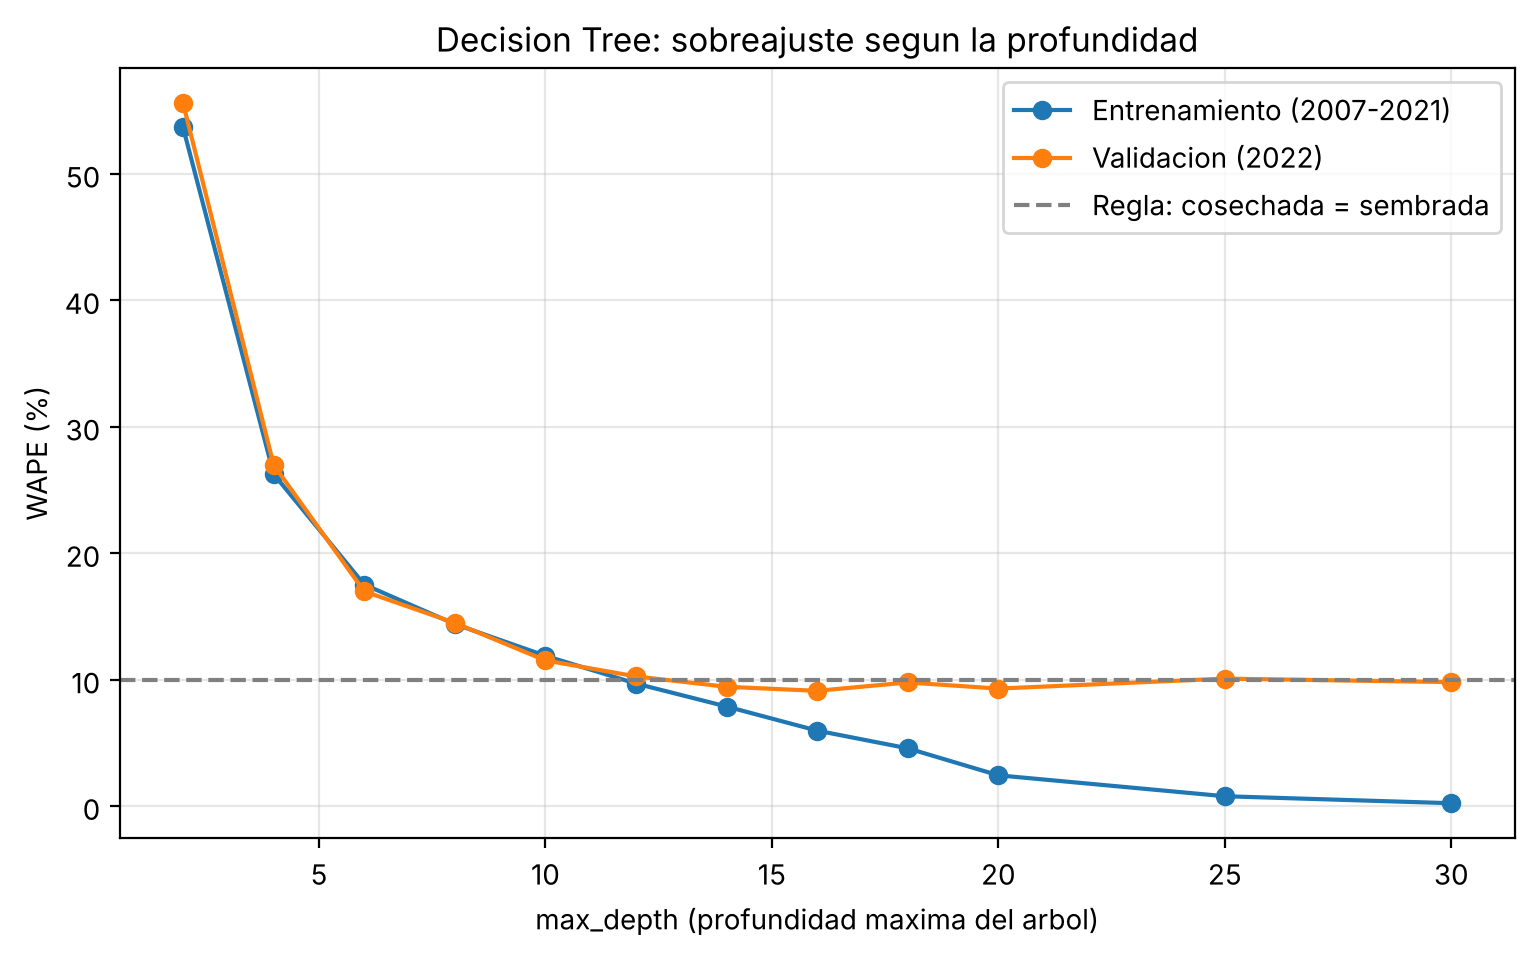

PASO M1c: Ejecutado correctamente
-------------------------------


In [6]:
# =========================================================
# PASO M1c: Curva de sobreajuste (entrenamiento vs validacion)
# =========================================================
print("PASO M1c: Curva de sobreajuste")
import matplotlib.pyplot as plt

profundidades = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 25, 30]
curva = []
for profundidad in profundidades:
    params = {**mejores, "max_depth": profundidad}
    modelo = DecisionTreeRegressor(random_state=SEMILLA, **params)
    modelo.fit(X_entreno, y_entreno)
    est_entreno = a_hectareas(modelo.predict(X_entreno), entreno)
    est_valid = a_hectareas(modelo.predict(X_validacion), validacion)
    curva.append({"max_depth": profundidad,
                  "WAPE_entrenamiento": metricas(entreno["area_cosechada"].values, est_entreno)["WAPE_%"],
                  "WAPE_validacion": metricas(validacion["area_cosechada"].values, est_valid)["WAPE_%"],
                  "hojas": modelo.get_n_leaves()})
curva = pd.DataFrame(curva)
print(curva.round(2))

wape_base_valid = metricas(validacion["area_cosechada"].values,
                           validacion["area_sembrada"].values)["WAPE_%"]

plt.figure(figsize=(9, 5))
plt.plot(curva["max_depth"], curva["WAPE_entrenamiento"], marker="o", label="Entrenamiento (2007-2021)")
plt.plot(curva["max_depth"], curva["WAPE_validacion"], marker="o", label="Validacion (2022)")
plt.axhline(wape_base_valid, color="gray", linestyle="--", label="Regla: cosechada = sembrada")
plt.xlabel("max_depth (profundidad maxima del arbol)")
plt.ylabel("WAPE (%)")
plt.title("Decision Tree: sobreajuste segun la profundidad")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(RUTA + "dt_curva_sobreajuste.png", dpi=150, bbox_inches="tight")
plt.show()
print("PASO M1c: Ejecutado correctamente")
print("-------------------------------")

In [7]:
# =========================================================
# PASO M2: Modelo final (entrena 2007-2022) y prueba (2023-2025)
# =========================================================
print("PASO M2: Modelo final y prueba")
entreno_final = df[df["anio"] <= ANIO_VALIDACION].copy()
X_final = construir_X(entreno_final, entreno_final)
X_prueba = construir_X(entreno_final, prueba)

modelo_final = DecisionTreeRegressor(random_state=SEMILLA, **mejores)
modelo_final.fit(X_final, objetivo(entreno_final))
estimada_prueba = a_hectareas(modelo_final.predict(X_prueba), prueba)

resultados = tabla_resultados(entreno_final, prueba, estimada_prueba, NOMBRE_MODELO)
predicciones = tabla_predicciones(prueba, estimada_prueba, NOMBRE_MODELO)
print(resultados[resultados["grupo"] == "TOTAL"])

# Archivos para unificar los 4 notebooks
pruebas.to_csv(RUTA + "validacion_" + NOMBRE_MODELO + ".csv", index=False)
resultados.to_csv(RUTA + "resultados_" + NOMBRE_MODELO + ".csv", index=False)
predicciones.to_csv(RUTA + "predicciones_" + NOMBRE_MODELO + ".csv", index=False, encoding="utf-8-sig")
print("PASO M2: Ejecutado correctamente")
print("-------------------------------")

PASO M2: Modelo final y prueba


/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_217/3102274135.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

                               modelo  grupo     WAPE_%     MAE_ha     RMSE_ha        R2
0                       Decision Tree  TOTAL  10.204735  31.042839  244.486096  0.973367
9          Base: cosechada = sembrada  TOTAL  11.997016  36.494964  352.462822  0.944647
18  Base: disponible x tasa historica  TOTAL  14.222109  43.263704  434.935619  0.915712


PASO M2: Ejecutado correctamente
-------------------------------


---
# 5. Análisis de resultados del Decision Tree

A partir de aquí ya **no se entrena ni se ajusta nada**: solo se analiza el modelo final y sus
predicciones de 2023–2025. Las gráficas se guardan en la carpeta `EVA` de Drive para usarlas en
las diapositivas.

PASO A1: Comparacion contra las reglas base
                                   WAPE_%  MAE_ha  RMSE_ha     R2
modelo                                                           
Decision Tree                      10.205  31.043  244.486  0.973
Base: cosechada = sembrada         11.997  36.495  352.463  0.945
Base: disponible x tasa historica  14.222  43.264  434.936  0.916

modelo                                              Decision Tree  Base: cosechada = sembrada  Base: disponible x tasa historica
grupo                                                                                                                           
CULTIVOS TROPICALES TRADICIONALES                            6.57                       14.80                               9.08
OLEAGINOSAS                                                  7.68                        8.46                              18.54
FRUTALES                                                     9.31                        9.04                

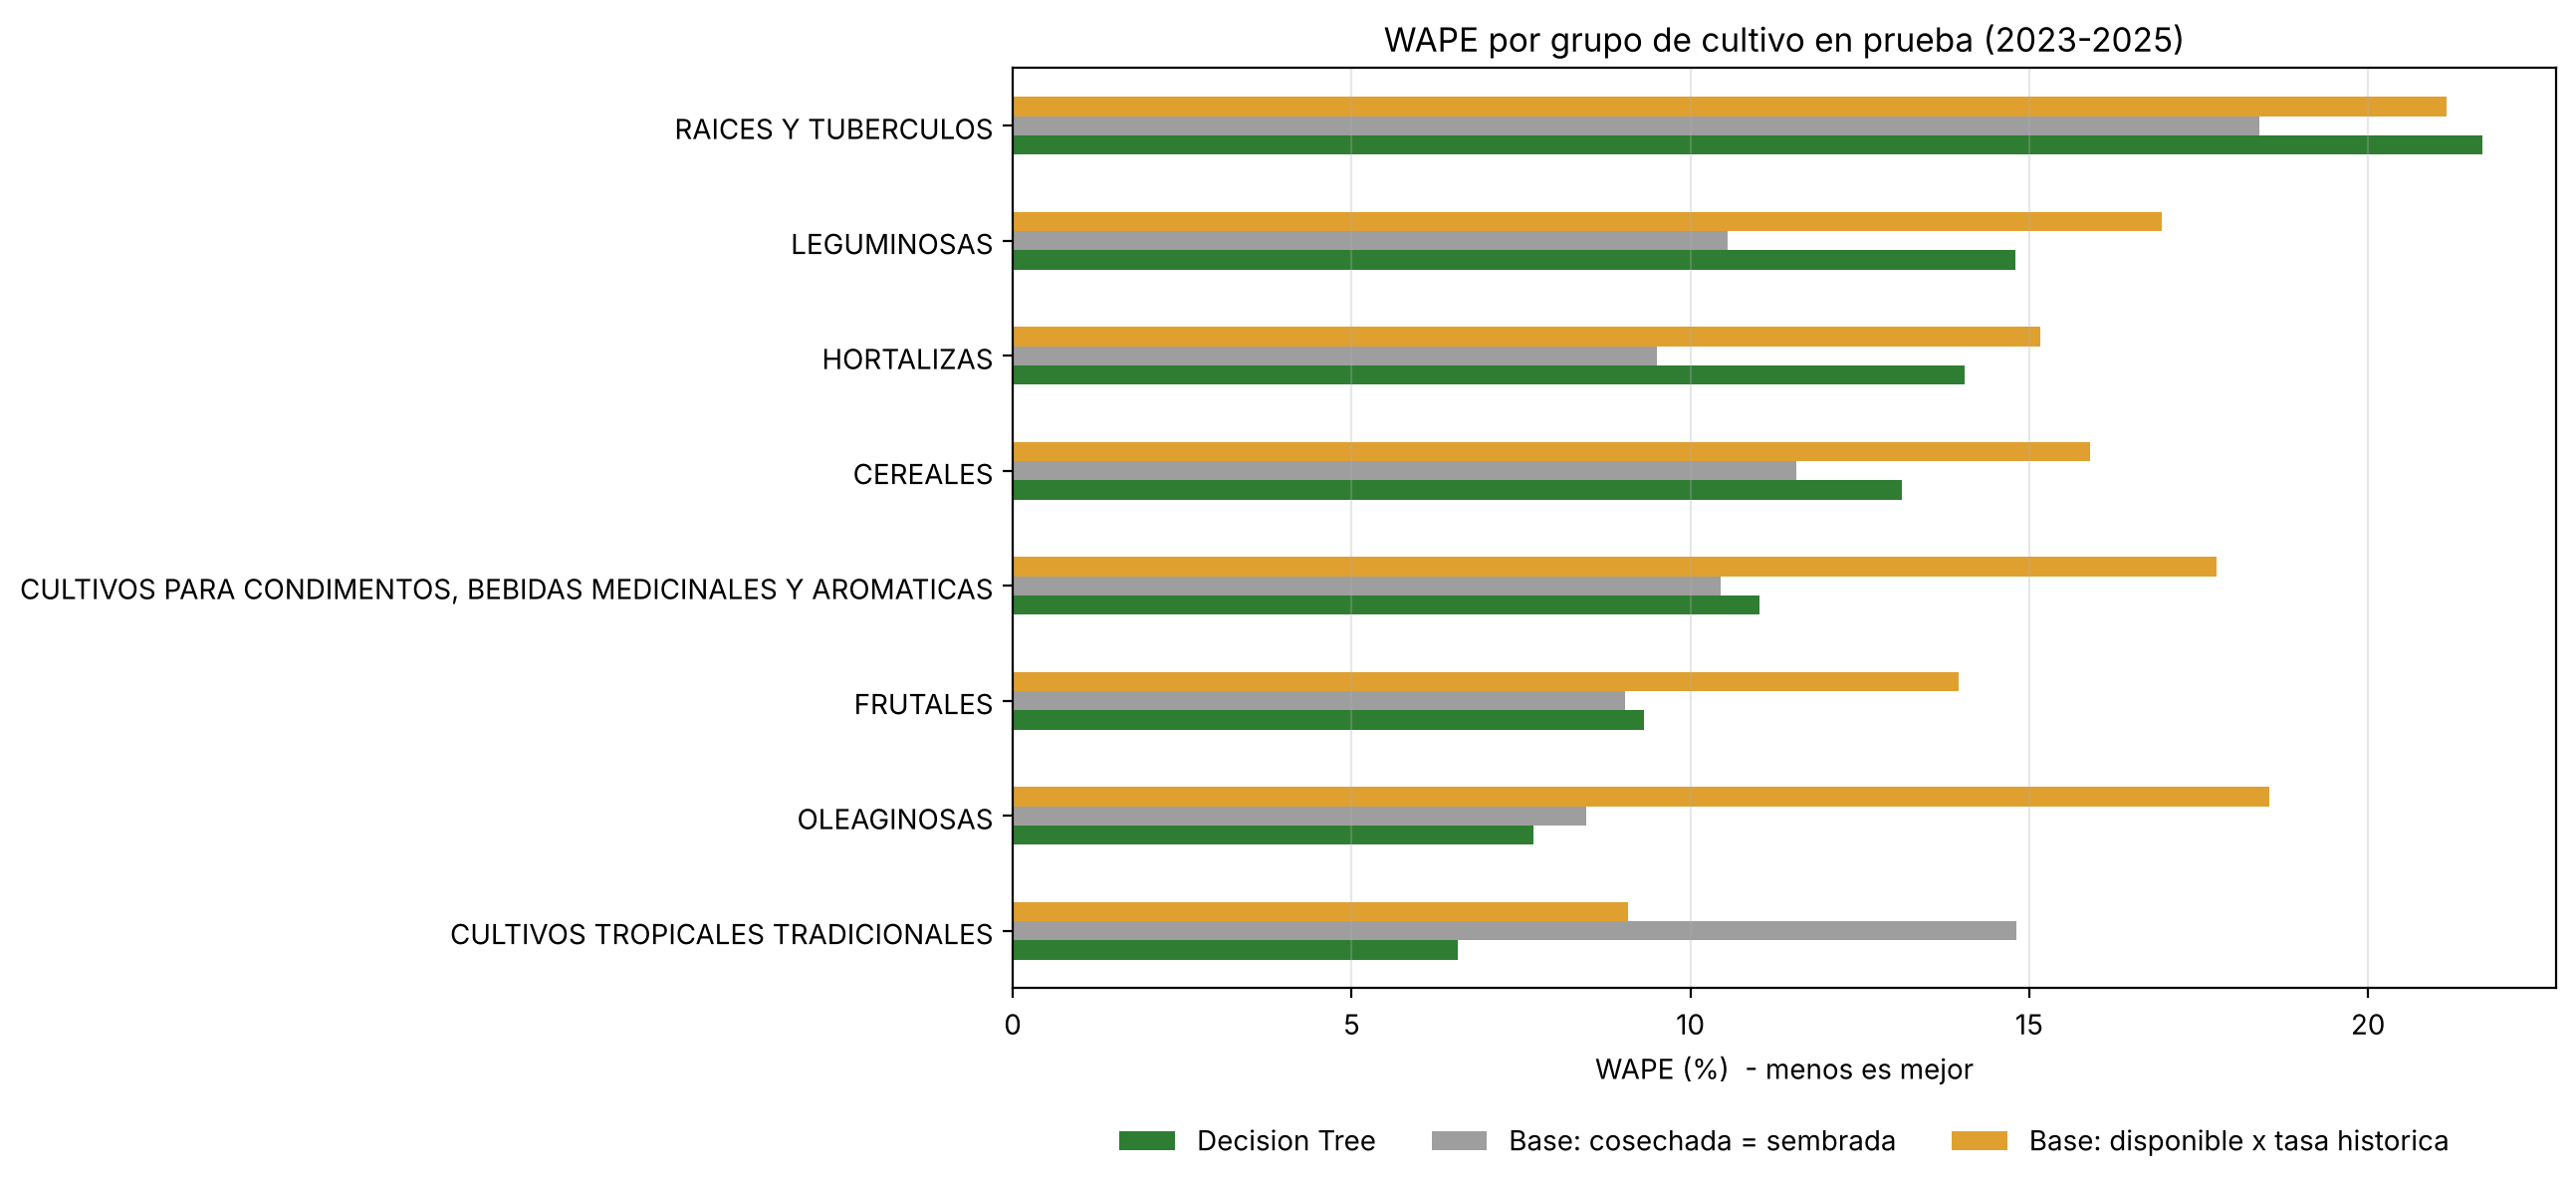

PASO A1: Ejecutado correctamente
-------------------------------


In [8]:
# =========================================================
# PASO A1: Comparacion contra las reglas base, total y por grupo
# =========================================================
print("PASO A1: Comparacion contra las reglas base")

total = resultados[resultados["grupo"] == "TOTAL"].set_index("modelo")
print(total[["WAPE_%", "MAE_ha", "RMSE_ha", "R2"]].round(3))
print()

# WAPE por grupo: modelo vs regla "cosechada = sembrada"
por_grupo = (resultados[resultados["grupo"] != "TOTAL"]
             .pivot(index="grupo", columns="modelo", values="WAPE_%"))
por_grupo = por_grupo[[NOMBRE_MODELO, "Base: cosechada = sembrada", "Base: disponible x tasa historica"]]
por_grupo = por_grupo.sort_values(NOMBRE_MODELO)
print(por_grupo.round(2))

ax = por_grupo.plot(kind="barh", figsize=(10, 6), color=["#2E7D32", "#9E9E9E", "#E0A030"])
ax.set_xlabel("WAPE (%)  - menos es mejor")
ax.set_ylabel("")
ax.set_title("WAPE por grupo de cultivo en prueba (2023-2025)")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.grid(axis="x", alpha=0.3)
plt.savefig(RUTA + "dt_wape_por_grupo.png", dpi=150, bbox_inches="tight")
plt.show()
print("PASO A1: Ejecutado correctamente")
print("-------------------------------")

In [9]:
# =========================================================
# PASO A2: Donde acierta y donde falla el arbol
# =========================================================
# En el 42,5% de las filas se cosecha exactamente lo sembrado: ahi la regla
# "cosechada = sembrada" no se equivoca nunca. El reto real son las filas con perdida.
print("PASO A2: Donde acierta y donde falla")

real = prueba["area_cosechada"].values
base = prueba["area_sembrada"].values
sin_perdida = (prueba["area_cosechada"] >= prueba["area_sembrada"]).values

filas = []
for nombre, mascara in [("Sin perdida (cosechada >= sembrada)", sin_perdida),
                        ("Con perdida (cosechada < sembrada)", ~sin_perdida)]:
    filas.append({"tipo_de_fila": nombre,
                  "filas": int(mascara.sum()),
                  "WAPE_arbol_%": metricas(real[mascara], estimada_prueba[mascara])["WAPE_%"],
                  "WAPE_regla_%": metricas(real[mascara], base[mascara])["WAPE_%"]})
print(pd.DataFrame(filas).round(2))
print()

# Error por anio de prueba
por_anio = []
for anio in ANIOS_PRUEBA:
    m = (prueba["anio"] == anio).values
    por_anio.append({"anio": anio,
                     "WAPE_arbol_%": metricas(real[m], estimada_prueba[m])["WAPE_%"],
                     "WAPE_regla_%": metricas(real[m], base[m])["WAPE_%"]})
print(pd.DataFrame(por_anio).round(2))
print("PASO A2: Ejecutado correctamente")
print("-------------------------------")

PASO A2: Donde acierta y donde falla
                          tipo_de_fila  filas  WAPE_arbol_%  WAPE_regla_%
0  Sin perdida (cosechada >= sembrada)  22994          7.30          1.02
1   Con perdida (cosechada < sembrada)  23340         11.64         17.43

   anio  WAPE_arbol_%  WAPE_regla_%
0  2023          9.20         10.86
1  2024         11.31         13.31
2  2025         10.15         11.86
PASO A2: Ejecutado correctamente
-------------------------------


PASO A3: Importancia de las variables
log_area_disponible            0.6588
log_area_sembrada              0.2090
log_cosechada_ant              0.0871
log_sembrada_ant               0.0157
tasa_hist                      0.0106
anio                           0.0034
altura_msnm                    0.0028
permanente                     0.0022
hay_hist                       0.0007
cultivo_mod_PALMA DE ACEITE    0.0005
rep2019                        0.0004
cultivo_mod_AGUACATE           0.0003
cod_dep_99                     0.0003
cod_dep_08                     0.0003
cod_dep_13                     0.0003
dtype: float64

Importancia agrupada por variable original:
log_area_disponible    0.6588
log_area_sembrada      0.2090
log_cosechada_ant      0.0871
log_sembrada_ant       0.0157
tasa_hist              0.0106
cultivo_mod            0.0044
cod_dep                0.0037
anio                   0.0034
altura_msnm            0.0028
permanente             0.0022
grupo                  0.0009
ha

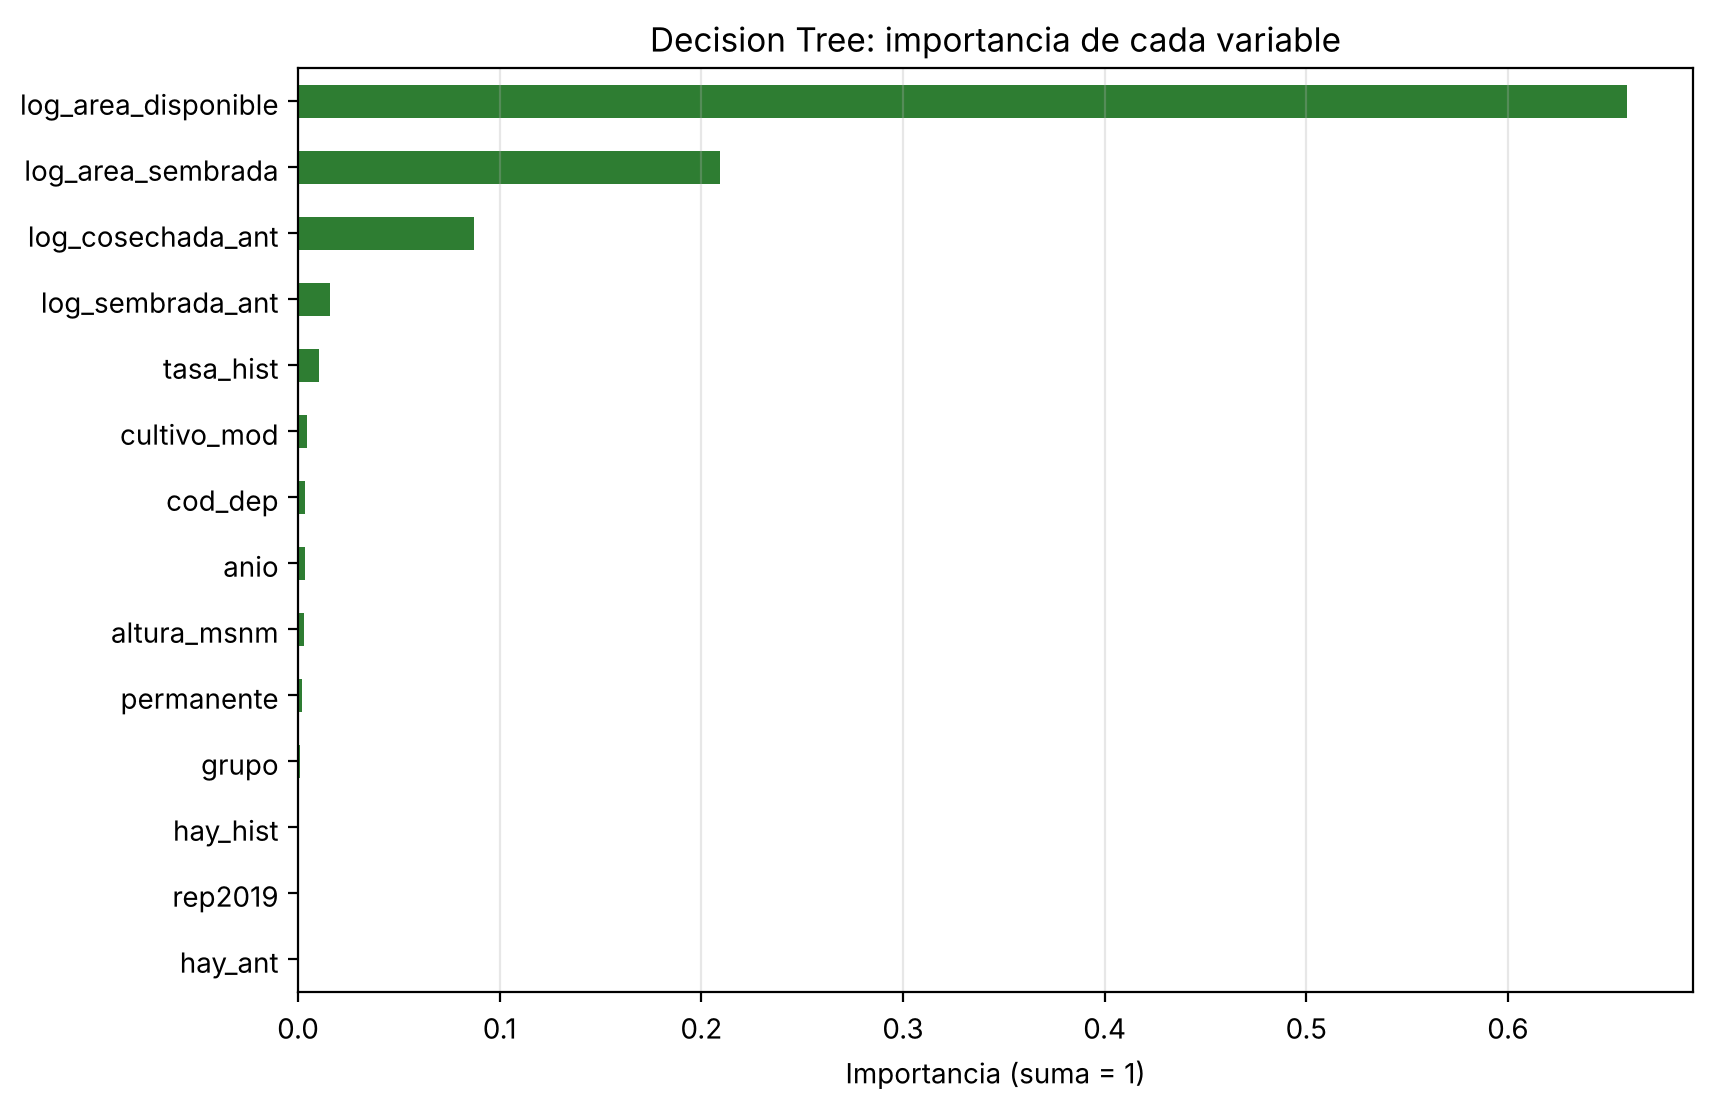

PASO A3: Ejecutado correctamente
-------------------------------


In [10]:
# =========================================================
# PASO A3: Importancia de las variables
# =========================================================
# Cuanto reduce el error cada variable en todas las divisiones del arbol (suma 1).
print("PASO A3: Importancia de las variables")

importancia = pd.Series(modelo_final.feature_importances_, index=X_final.columns)

# a) Las 15 columnas mas importantes
top = importancia.sort_values(ascending=False).head(15)
print(top.round(4))

# b) Importancia agrupada: se suman las columnas one-hot de cada variable original
def variable_original(columna):
    for prefijo in ["grupo_", "cultivo_mod_", "cod_dep_"]:
        if columna.startswith(prefijo):
            return prefijo[:-1]
    return columna
agrupada = importancia.groupby(variable_original).sum().sort_values(ascending=False)
print()
print("Importancia agrupada por variable original:")
print(agrupada.round(4))

agrupada.sort_values().plot(kind="barh", figsize=(9, 6), color="#2E7D32")
plt.xlabel("Importancia (suma = 1)")
plt.title("Decision Tree: importancia de cada variable")
plt.grid(axis="x", alpha=0.3)
plt.savefig(RUTA + "dt_importancia_variables.png", dpi=150, bbox_inches="tight")
plt.show()
print("PASO A3: Ejecutado correctamente")
print("-------------------------------")

### Un árbol pequeño para explicar cómo decide

El modelo final tiene miles de hojas y no se puede dibujar. Para la exposición se entrena un
árbol **de solo 3 niveles** con los mismos datos: no es el modelo que se evalúa, es una
"foto simplificada" de las primeras preguntas que hace el árbol.

Los valores de cada hoja (`value`) están en escala `log(1 + área)`. Para pasarlos a hectáreas:
`área = e^value − 1` (por ejemplo, `value = 3` ≈ 19 ha y `value = 6` ≈ 402 ha).

PASO A4: Dibujo de un arbol de 3 niveles


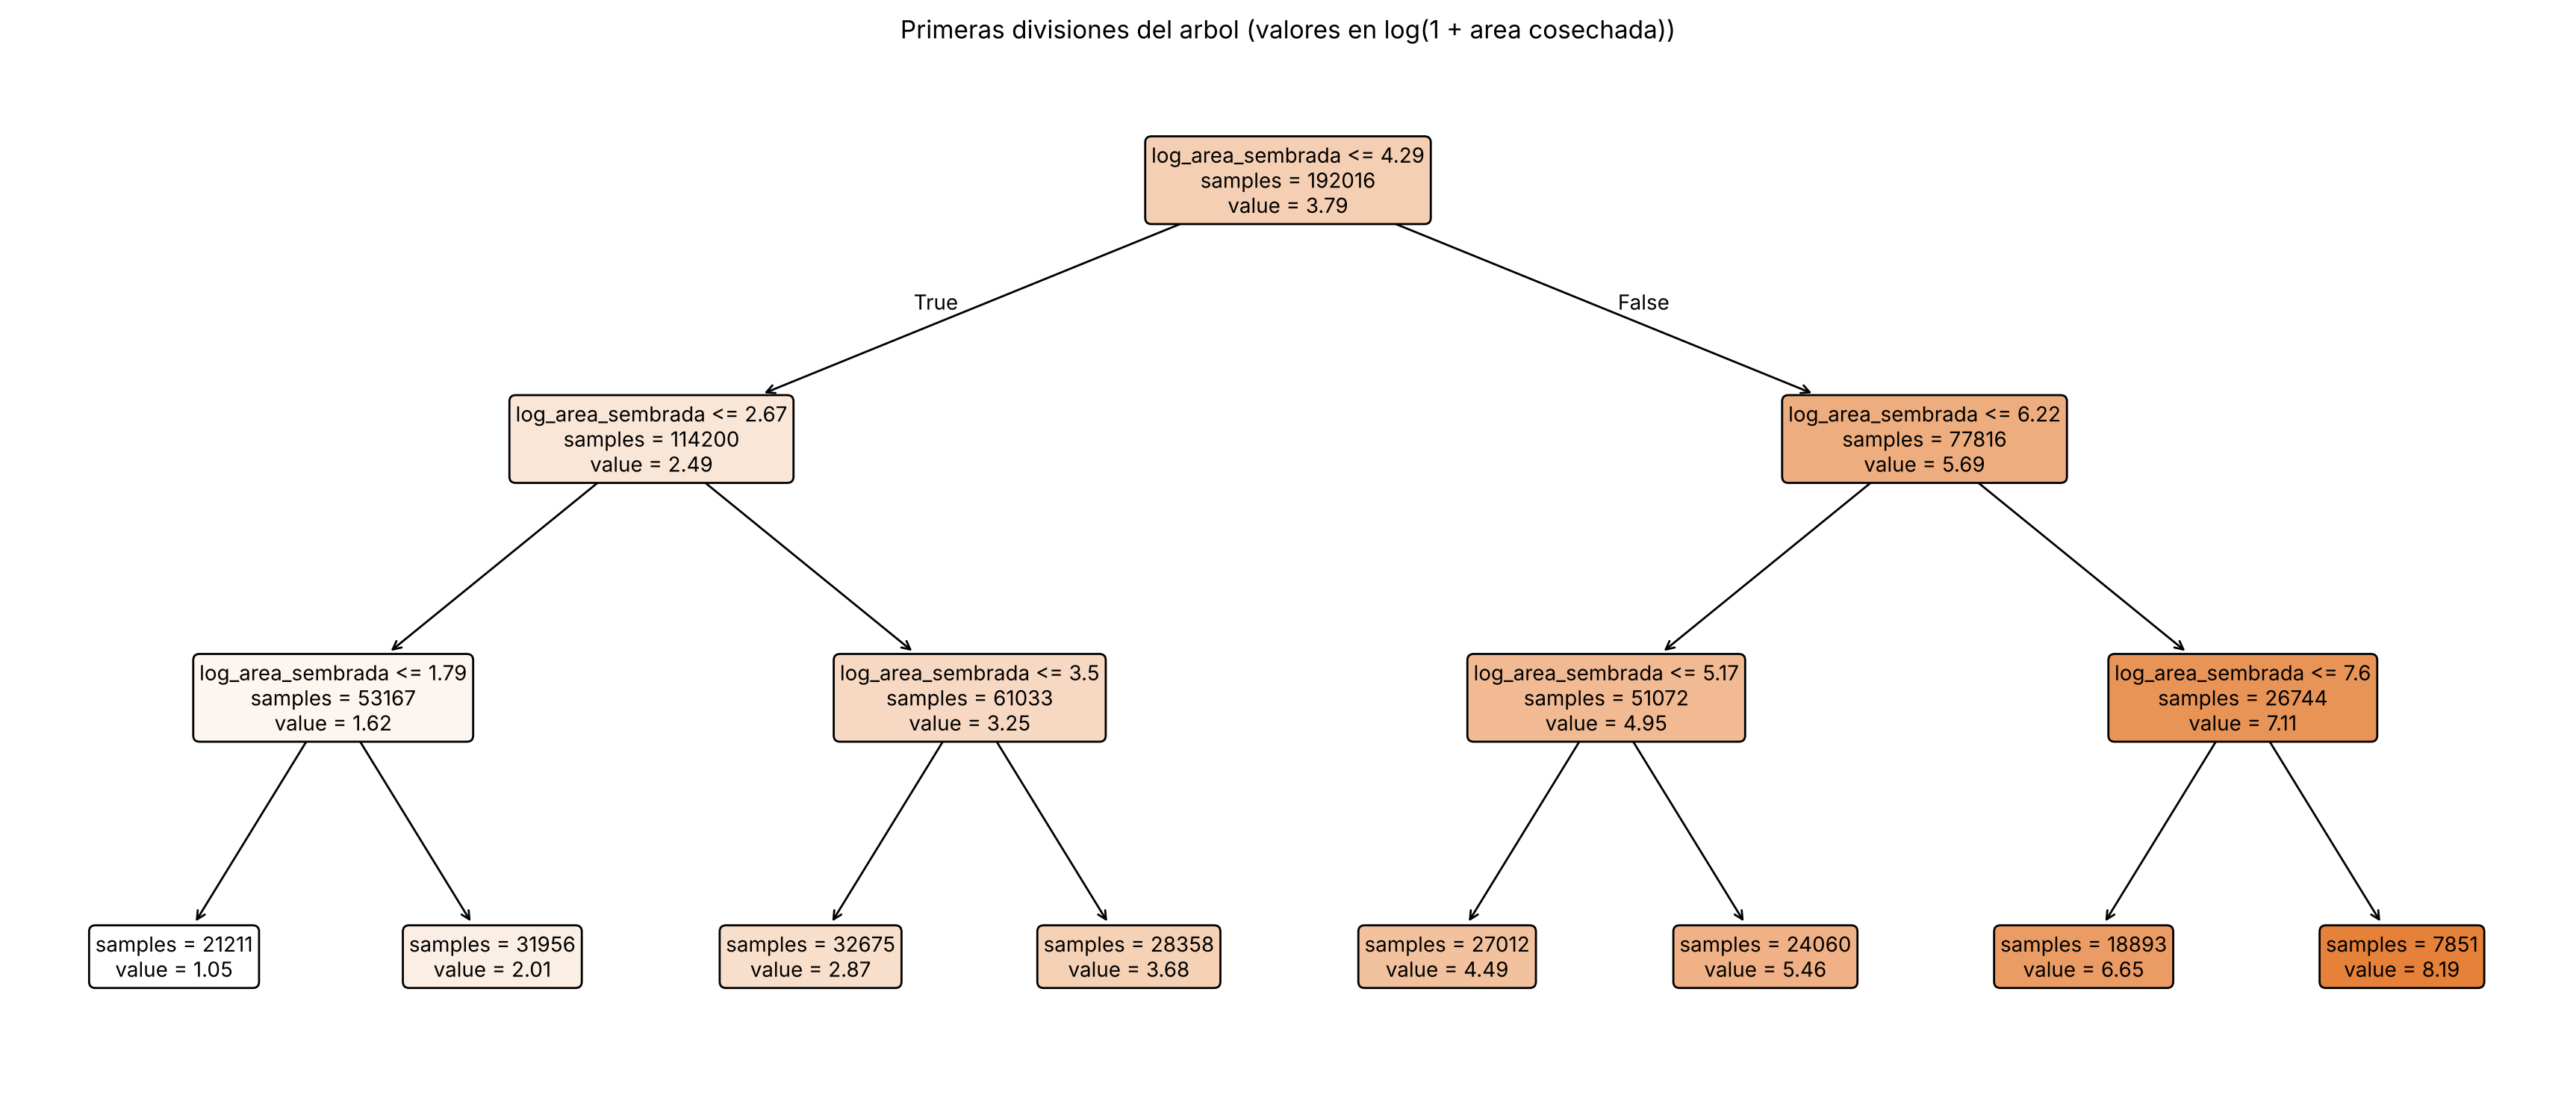

PASO A4: Ejecutado correctamente
-------------------------------


In [11]:
# =========================================================
# PASO A4: Dibujo de un arbol de 3 niveles (solo para explicar)
# =========================================================
print("PASO A4: Dibujo de un arbol de 3 niveles")
from sklearn.tree import plot_tree

arbol_simple = DecisionTreeRegressor(max_depth=3, random_state=SEMILLA)
arbol_simple.fit(X_final, objetivo(entreno_final))

plt.figure(figsize=(22, 9))
plot_tree(arbol_simple, feature_names=list(X_final.columns), filled=True,
          rounded=True, precision=2, fontsize=10, impurity=False)
plt.title("Primeras divisiones del arbol (valores en log(1 + area cosechada))")
plt.savefig(RUTA + "dt_arbol_3_niveles.png", dpi=150, bbox_inches="tight")
plt.show()
print("PASO A4: Ejecutado correctamente")
print("-------------------------------")

PASO A5: Real vs estimada


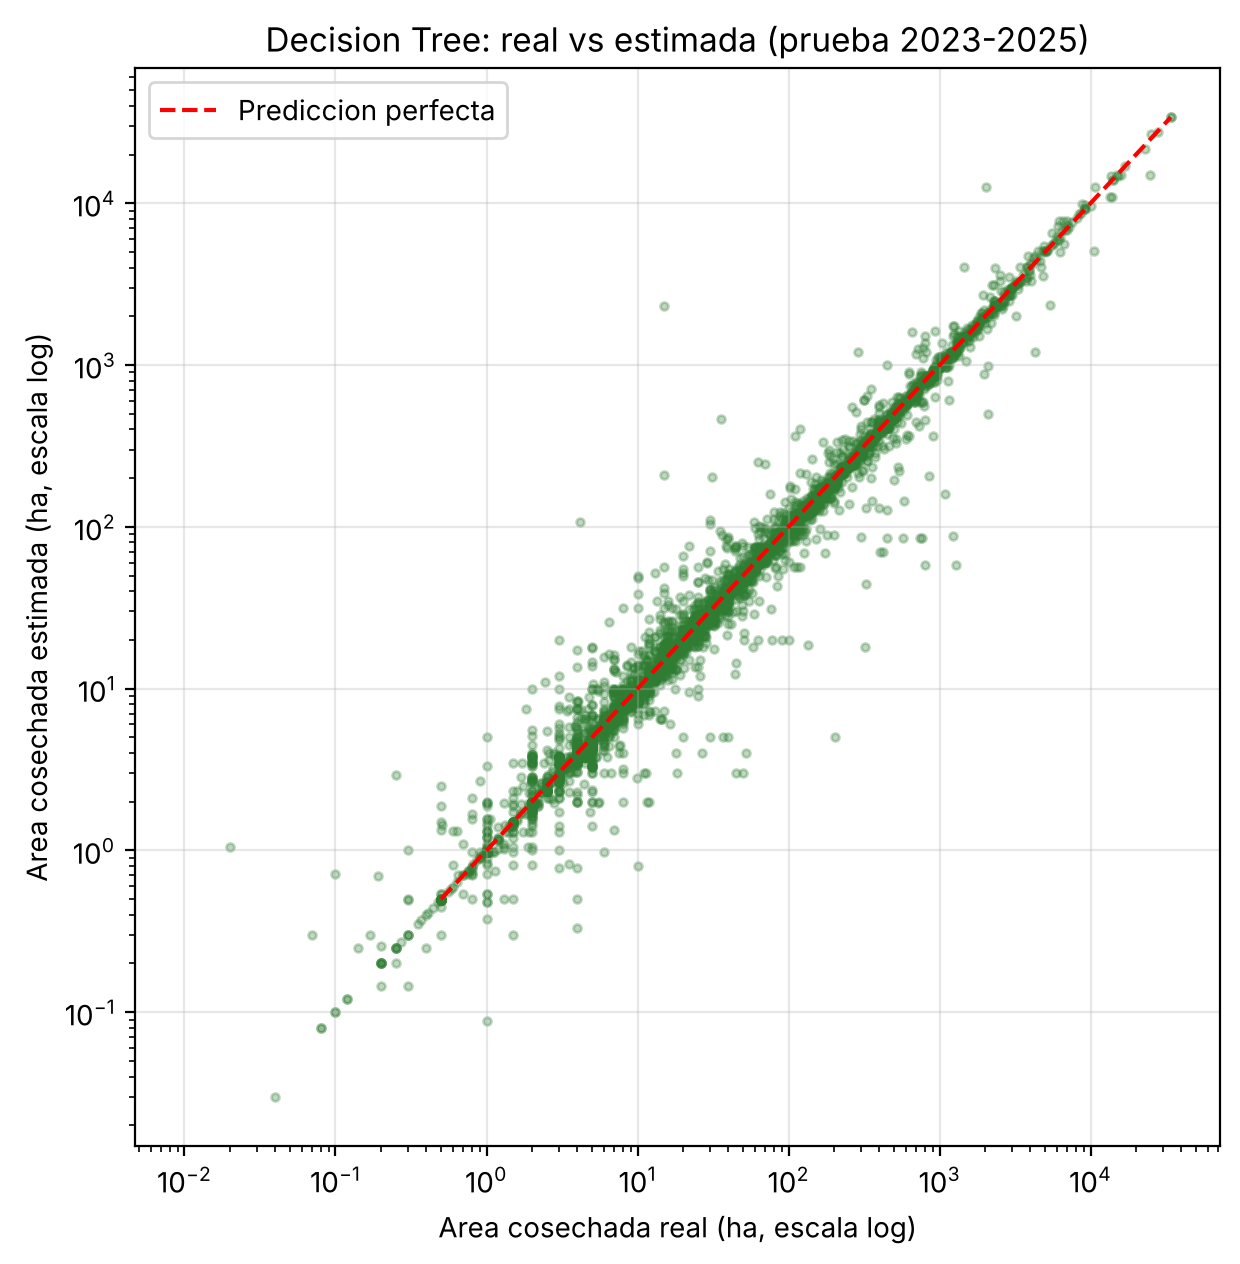

PASO A5: Ejecutado correctamente
-------------------------------


In [12]:
# =========================================================
# PASO A5: Real vs estimada (muestra de 5.000 filas de prueba)
# =========================================================
print("PASO A5: Real vs estimada")
muestra = predicciones.sample(min(5000, len(predicciones)), random_state=SEMILLA)

plt.figure(figsize=(7, 7))
plt.scatter(muestra["area_cosechada"], muestra["area_cosechada_estimada"],
            s=8, alpha=0.3, color="#2E7D32")
limite = muestra[["area_cosechada", "area_cosechada_estimada"]].max().max()
plt.plot([0.5, limite], [0.5, limite], color="red", linestyle="--", label="Prediccion perfecta")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Area cosechada real (ha, escala log)")
plt.ylabel("Area cosechada estimada (ha, escala log)")
plt.title("Decision Tree: real vs estimada (prueba 2023-2025)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(RUTA + "dt_real_vs_estimada.png", dpi=150, bbox_inches="tight")
plt.show()
print("PASO A5: Ejecutado correctamente")
print("-------------------------------")

In [13]:
# =========================================================
# PASO A6: Resumen para las diapositivas
# =========================================================
print("PASO A6: Resumen para las diapositivas")
wape_modelo = total.loc[NOMBRE_MODELO, "WAPE_%"]
wape_regla = total.loc["Base: cosechada = sembrada", "WAPE_%"]
wape_tasa = total.loc["Base: disponible x tasa historica", "WAPE_%"]
diferencia = wape_regla - wape_modelo

print("=" * 60)
print("DECISION TREE - RESULTADOS EN PRUEBA (2023-2025)")
print("=" * 60)
print("Hiperparametros elegidos (validacion 2022):", mejores)
print("Hojas del arbol final :", modelo_final.get_n_leaves(),
      "| Profundidad real:", modelo_final.get_depth())
print()
print("WAPE Decision Tree                :", round(wape_modelo, 2), "%")
print("WAPE regla 'cosechada = sembrada' :", round(wape_regla, 2), "%")
print("WAPE regla 'disponible x tasa'    :", round(wape_tasa, 2), "%")
print()
if diferencia > 0.3:
    print("-> El arbol le GANA a la regla simple por", round(diferencia, 2), "puntos de WAPE.")
elif diferencia >= -0.3:
    print("-> El arbol queda practicamente EMPATADO con la regla simple (",
          round(diferencia, 2), "puntos).")
else:
    print("-> El arbol PIERDE contra la regla simple por", round(-diferencia, 2), "puntos de WAPE.")
print()
print("Mejor grupo :", por_grupo.index[0], "(", round(por_grupo.iloc[0, 0], 2), "% )")
print("Peor grupo  :", por_grupo.index[-1], "(", round(por_grupo.iloc[-1, 0], 2), "% )")
print("Variable mas importante:", agrupada.index[0],
      "(", round(agrupada.iloc[0] * 100, 1), "% de la importancia)")
print("=" * 60)
print("PASO A6: Ejecutado correctamente")
print("-------------------------------")

PASO A6: Resumen para las diapositivas
DECISION TREE - RESULTADOS EN PRUEBA (2023-2025)
Hiperparametros elegidos (validacion 2022): {'max_depth': 16, 'min_samples_leaf': 1, 'max_features': 0.7}
Hojas del arbol final : 13111 | Profundidad real: 16

WAPE Decision Tree                : 10.2 %
WAPE regla 'cosechada = sembrada' : 12.0 %
WAPE regla 'disponible x tasa'    : 14.22 %

-> El arbol le GANA a la regla simple por 1.79 puntos de WAPE.

Mejor grupo : CULTIVOS TROPICALES TRADICIONALES ( 6.57 % )
Peor grupo  : RAICES Y TUBERCULOS ( 21.69 % )
Variable mas importante: log_area_disponible ( 65.9 % de la importancia)
PASO A6: Ejecutado correctamente
-------------------------------


---
# 6. Conclusiones del Decision Tree

*(Completar con los números que imprime el PASO A6 después de correr el notebook.)*

**Resultado.** En prueba (2023–2025) el árbol tiene un WAPE de **__ %**, frente a **__ %** de la
regla "cosechada = sembrada" y **__ %** de la regla "disponible × tasa histórica".

**¿Por qué da ese resultado?**
- En el 42,5 % de las filas se cosecha exactamente lo sembrado. Ahí la regla simple no se equivoca,
  y el árbol, en cambio, predice el *promedio* de su hoja, así que puede introducir un error pequeño
  donde no lo había.
- Donde sí hay pérdidas, el árbol usa la historia de la serie (`tasa_hist`, año anterior) para
  anticiparlas. Esa es la parte en la que puede ganarle a la regla (ver PASO A2).
- Un solo árbol produce predicciones "en escalones": todas las filas de una hoja reciben el mismo
  valor. Por eso le cuesta afinar, y por eso un conjunto de árboles (Random Forest) suele mejorarlo.
- Es sensible a los datos de entrenamiento: con otra semilla o con un año más de datos, las primeras
  divisiones pueden cambiar.

**Alcances**
- Es el modelo más fácil de explicar: se puede dibujar y leer como reglas "si… entonces…".
- No necesita escalar los datos y entrena en segundos.
- Muestra qué variables pesan más (PASO A3).

**Limitaciones**
- Sin límites de profundidad y de tamaño de hoja, memoriza el entrenamiento (sobreajuste, PASO M1c).
- No extrapola: nunca predice un valor por fuera de lo que vio en entrenamiento.
- No capta perfectamente relaciones suaves (como "a más sembrado, más cosechado"), solo las aproxima
  por tramos.